### Mouse brain - cell2location paper, Figure 2 (mb01)

**Paper**: Kleshchevnikov V. *et al.* *Comprehensive mapping of tissue cell architecture via integrated single cell and spatial transcriptomics.* bioRxiv 2020.11.15.378125 (published as *Cell2location maps fine-grained cell types in spatial transcriptomics*, Nat Biotechnol 40, 661-671, 2022).


The authores: "We generated matched single nucleus (sn) and Visium spatial RNA-seq (10X Genomics) profiles of adjacent mouse brain sections that contain multiple regions from the telencephalon and diencephalon (Fig 2A). 

To assess the biological and intra-organ technical variation in spatial mapping, we assayed two mouse brains and serial tissue sections from each brain (total of 3 and 2 matched sections from two animals, respectively, and an extra section for snRNA-seq), creating a rich multi-modal and replicated transcriptomic dataset."


![Fig 2A](../mouse_brain/figures/fig_2A.png)


This notebook reproduces the mouse brain panels of **Fig 2** 

#### Libs: **src/libs**

- **single_cell_lib** methods:
  - Class: SingleCell
    - generic Scanpy
    - Squidpy 
    - cell2location - 
    - LIANA 
    - **DEFAULT_PARAMS**

- **single_cell_neuro_lib** - mouse brain methods and **NEURO_PARAMS**
  - Classe: SingleCellNeuro(SingleCell)

<br>

| section | content | paper |
|---|---|---|
| 1 | open the h5ad files | |
| 2 | components and attributes | |
| 3 | filter data | Methods: genes < 5000, mito < 10%, doublets < 0.2 |
| 4 | quality control | Fig S4 |
| 5 | UMAP: broad classes and 59 subtypes | Fig 2B |
| 6 | anatomical regions, major regional subtypes, sparse cell types, fine anatomical subtypes | Fig 2C-F |
| 7 | Slide-seq V2 mapping | Fig 2H |
| 8 | quantitative validation workflow (manually dissected layers) | Fig 2I |
| 9 | heatmap of relative cell subtype proportion per layer | Fig 2J |

**Data** (**mouse_brain/data**): 5 Visium sections (E-MTAB-11114) and snRNA-seq (E-MTAB-11115) from the cell2location server; the paper's own cell2location map with region clusters (sections ST8059048, mouse 1 and ST8059051, mouse 2); squidpy Slide-seqV2; Allen mouse cortex + hippocampus Smart-seq (Yao et al. 2020).

<div class="alert alert-warning">
<b>Differences from the paper</b>
</div>

- **Fig 2C-F** use the paper's precomputed cell2location map (2 of the 5 sections); region names come from cell-type enrichment rules (**region_celltype_map**), not from manual annotation.

![fig 2C-F](../mouse_brain/figures/fig2C-F.png)


- **Fig 2H** uses squidpy's Slide-seqV2 hippocampus puck (41,786 beads, 4,000 HVGs, counts recovered from log-normalised X), not the paper's 53,208-bead section; mapping with current cell2location (v0.1.5) priors.

![fig 2H](../mouse_brain/figures/Fig2H.png)


- **Fig 2I/J**: the manual Loupe layer annotation of SSp is not published; cortical layers are taken from the region clusters (all cortex, not SSp only). The Allen taxonomy release gives 104 + 34 cell types (paper: 98 + 23).

![fig 2I-J](../mouse_brain/figures/Fig2I-Jb.png)


- cell2location runs in the sandbox were done on CPU with reduced epochs (tags **cpu3000**, **cpu2000**); rerun with **src/programs/run_c2l_mouse_brain.py --max_epochs 30000 --accelerator gpu** and change the tags below.



## Loading packages

In [51]:
import os, sys
from pathlib import Path
from importlib.metadata import version
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import anndata as ad
import scanpy as sc

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['pdf.fonttype'] = 42

ROOT0 = Path('/home/flavio/uv/cell_cell_communication')
ROOT_SRC = ROOT0 / 'src'
if str(ROOT_SRC) not in sys.path:
    sys.path.append(str(ROOT_SRC))

from libs.single_cell_neuro_lib import SingleCellNeuro, NEURO_PARAMS
from libs.matplotlib_figure_style import apply_figure_style
from libs.Basic import pdwritecsv, pdreadcsv

pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 250)
print({p: version(p) for p in ['scanpy', 'squidpy', 'anndata', 'cell2location', 'liana']})

{'scanpy': '1.12.4', 'squidpy': '1.8.3', 'anndata': '0.13.4', 'cell2location': '0.1.5', 'liana': '1.10.0'}


## Parameters

All file names, cutoffs and model settings are set here. **params** overrides **NEURO_PARAMS** / **DEFAULT_PARAMS**; **scn.calc_df_params()** lists every parameter.

In [2]:
project = 'mouse_brain'

# ---- input files (relative to root_data = ROOT0 / project / 'data')
fname_visium     = 'visium_mouse_brain_5sections.h5ad'
fname_snrna      = 'snrna/all_cells_20200625.h5ad'
fname_annot      = 'snrna/snRNA_annotation_astro_subtypes_refined59_20200823.csv'
fname_umap       = 'snrna/mouse_brain_snRNA_with_UMAP_cellxgene.h5ad'
fname_signatures = 'snrna/regression_signatures_sc.h5ad'
fname_map        = 'c2l_paper_map/sp_with_clusters.h5ad'
fname_slideseq   = 'slideseq/slideseqv2.h5ad'
fname_allen      = 'allen_smartseq/allen_smartseq_SSp_PARPOSTPRE.h5ad'

# ---- output files (figures in root_figure, tables in root_result)
fig_qc_visium = 'mb01_qc_visium.png'
fig_qc_snrna  = 'mb01_qc_snrna.png'
fig_2B        = 'mb01_fig2B_umap.png'
fig_2C        = 'mb01_fig2C_regions_{lib}.png'
fig_2DEF      = 'mb01_fig2DEF_density_{lib}.png'
fig_2H        = 'mb01_fig2H_slideseq.png'
fig_2I        = 'mb01_fig2I_layers.png'
fig_2J        = 'mb01_fig2J_layer_heatmap.png'
tsv_regions   = 'mb01_region_clusters.tsv'
tsv_layer     = 'mb01_fig2J_layer_proportions.tsv'

# ---- cutoffs / settings (override NEURO_PARAMS)
params = dict(
    snrna_max_genes=5000,          # paper: genes per nucleus < 5000
    snrna_max_mt_frac=0.10,        # paper: mitochondrial fraction < 0.10
    # snrna_max_doublet=0.2,       # paper: scrublet < 0.2 (column absent in the public file -> skipped)
    density_quantile=0.992,        # colour cap of density panels
    region_label_override={'11': 'CTX_L1', '21': 'edge_LowQ'},   # justified in section 6 (edge fraction)
    accelerator='auto',            # 'gpu' on a CUDA machine
)
library_main = 'ST8059048'         # section shown in Fig 2C-F, 2I (mouse 1); the other mapped one is ST8059051

# ---- cell2location runs (cached by src/programs/run_c2l_mouse_brain.py)
c2l_tag_slideseq     = 'cpu2000'   # results/c2l_slideseq_<tag>
c2l_tag_allen        = 'cpu3000'   # results/c2l_allen_ssp_<tag>
c2l_train_if_missing = False       # True -> train here when the cache is missing (GPU recommended)
c2l_max_epochs       = 30000       # paper: 30000

apply_figure_style()
scn = SingleCellNeuro(ROOT0, project, params=params)
root_data, root_figure, root_result = scn.root_data, scn.root_figure, scn.root_result
print(scn)
print(root_data, '\n', sorted(os.listdir(root_data)))

SingleCellNeuro(project='mouse_brain', adata=None, symbol_col='SYMBOL', sample_col='sample')
/home/flavio/uv/cell_cell_communication/mouse_brain/data 
 ['allen_smartseq', 'c2l_paper_map', 'inspect.txt', 'mouse_brain_visium_wo_cloupe_data', 'mouse_brain_visium_wo_cloupe_data.zip', 'slideseq', 'snrna', 'visium_hne.h5ad', 'visium_hne_liana_bivariate.h5ad', 'visium_mouse_brain_5sections.h5ad']


In [3]:
# params withou doublet correction
params

{'snrna_max_genes': 5000,
 'snrna_max_mt_frac': 0.1,
 'density_quantile': 0.992,
 'region_label_override': {'11': 'CTX_L1', '21': 'edge_LowQ'},
 'accelerator': 'auto'}

In [4]:
df_params = scn.calc_df_params()
df_params[df_params.value.astype(str) != df_params.default.astype(str)]

,parameter,value,default
77,region_label_override,"{'11': 'CTX_L1', '21': 'edge_LowQ'}",{}


### 1. Open the h5ad files

- **adata_vis**: 
  - 5 Visium sections merged (**download_mouse_brain_visium.py**), 
  - Ensembl **var_names**, symbols in **var['SYMBOL']**

- **adata_ref**: 
  - snRNA-seq raw counts, 
  - 6 samples (5 paired with Visium + 1 extra section)

In [5]:
adata_vis = scn.read_h5ad(fname_visium, set_self=False)
adata_ref = scn.read_h5ad(fname_snrna, set_self=False)
adata_vis, adata_ref

(AnnData object with n_obs × n_vars = 14968 × 31053
     obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position'
     var: 'SYMBOL', 'MT_gene'
     uns: 'spatial'
     obsm: 'spatial'
     layers: None (.X),
 AnnData object with n_obs × n_vars = 40572 × 31053
     obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode'
     var: 'feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt'
     layers: None (.X))

### 2. Components and attributes

In [6]:
scn.summary(adata_vis)

AnnData object with n_obs × n_vars = 14968 × 31053
    obs: 'in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position'
    var: 'SYMBOL', 'MT_gene'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)

X: {'type': 'csr_matrix', 'dtype': 'float32', 'shape': (14968, 31053), 'density': 0.1456, 'min': 1.0, 'max': 5308.0, 'integer': True, 'nnz_per_row': 4520.1}

obs columns (8): ['in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position']
var columns (2): ['SYMBOL', 'MT_gene']
obsm: {'spatial': (14968, 2)}
layers: [None]
uns: ['spatial']
  library ST8059048: images [('hires', (2000, 1969, 3)), ('lowres', (600, 591, 3))]
  library ST8059049: images [('hires', (2000, 1969, 3)), ('lowres', (600, 591, 3))]
  library ST8059050: images [('hires', (2000, 1968, 3)), ('lowres', (600, 590, 3))]
  library ST8059051: images [('hires', (2000, 1963, 3)), ('lowres', (600, 589, 3))]
  library ST8059052: images [('hires'

In [7]:
df_comp_vis = scn.calc_df_components(adata_vis)
df_comp_vis

,slot,key,type,shape
0,X,,csr_matrix,"(14968, 31053)"
1,obs,in_tissue,int64,"(14968,)"
2,obs,array_row,int64,"(14968,)"
3,obs,array_col,int64,"(14968,)"
4,obs,sample,category,"(14968,)"
5,obs,sample_name2,category,"(14968,)"
6,obs,image_name,category,"(14968,)"
7,obs,slide,category,"(14968,)"
8,obs,position,category,"(14968,)"
9,var,SYMBOL,object,"(31053,)"


In [8]:
df_comp_vis.groupby('slot').size().to_frame('n_keys').T

slot,X,layers,obs,obsm,uns,var
n_keys,1,1,8,1,1,2


In [60]:
adata_vis.obs.columns

Index(['in_tissue', 'array_row', 'array_col', 'sample', 'sample_name2', 'image_name', 'slide', 'position', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt',
       'pct_counts_mt'],
      dtype='object')

In [9]:
scn.sample_col

'sample'

In [61]:
df_sections = adata_vis.obs.groupby(scn.sample_col, observed=True).agg(
    n_spots=('in_tissue', 'size'), in_tissue=('in_tissue', 'sum'))
df_sections

,n_spots,in_tissue
sample,,
ST8059048,2987,2987
ST8059049,3499,3499
ST8059050,3497,3497
ST8059051,2409,2409
ST8059052,2576,2576


In [10]:
df_sections = adata_vis.obs.groupby(scn.sample_col, observed=True).agg(
    n_spots=('in_tissue', 'size'), in_tissue=('in_tissue', 'sum'))
df_sections['slide'] = [s for s in df_sections.index]
df_sections['image_hires'] = [adata_vis.uns['spatial'][s]['images']['hires'].shape for s in df_sections.index]
df_sections

,n_spots,in_tissue,slide,image_hires
sample,,,,
ST8059048,2987,2987,ST8059048,"(2000, 1969, 3)"
ST8059049,3499,3499,ST8059049,"(2000, 1969, 3)"
ST8059050,3497,3497,ST8059050,"(2000, 1968, 3)"
ST8059051,2409,2409,ST8059051,"(2000, 1963, 3)"
ST8059052,2576,2576,ST8059052,"(2000, 1950, 3)"


In [11]:
scn.summary(adata_ref)

AnnData object with n_obs × n_vars = 40572 × 31053
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode'
    var: 'feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'mt'
    layers: None (.X)

X: {'type': 'csr_matrix', 'dtype': 'float32', 'shape': (40572, 31053), 'density': 0.0819, 'min': 1.0, 'max': 3631.0, 'integer': True, 'nnz_per_row': 2542.5}

obs columns (11): ['n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'mt_frac', 'sample', 'barcode']
var columns (10): ['feature_types', 'genome', 'SYMBOL', 'n_cells_by_counts', 'mean_count

In [12]:
df_samples_ref = adata_ref.obs[scn.sample_col].value_counts().to_frame('n_nuclei')
df_samples_ref

,n_nuclei
sample,
5705STDY8058285,10260
5705STDY8058281,8253
5705STDY8058280,8150
5705STDY8058282,5799
5705STDY8058283,5215
5705STDY8058284,2895


### 3. Filter data

**snRNA-seq** (paper Methods) - kept:

  - nuclei with < 5000 detected genes, 
  - mitochondrial fraction < 0.10 and 
  - scrublet doublet score < 0.2. 
  
  - Visium spots contain more than one cell; therefore, no doublet-score corrections are needed.
  - The paper's annotation then defines the 40,532 nuclei used as reference.

  - For Visium you're right: a spot captures several cells, so doublet scores don't apply. 
  - For the snRNA-seq reference the paper did filter with scrublet < 0.2, but the 40,532 annotated nuclei are already the post-filtering set, so re-applying that cutoff adds nothing. I'll remove the doublet criterion and its warning, and state both reasons in the notebook.

In [13]:
adata_ref, df_filter_ref = scn.filter_snrna(adata_ref, inplace=False)
print(f"kept {df_filter_ref.attrs['kept']:,} of {df_filter_ref.attrs['total']:,} nuclei")
df_filter_ref

kept 40,570 of 40,572 nuclei


,criterion,threshold,failing,removed_here
0,n_genes_by_counts < max_genes,5000.0,2,2
1,pct_counts_mt < max_pct_mt,10.0,0,0


In [62]:
adata_ref, df_annot = scn.add_paper_annotation(fname_annot, adata_ref)
print(f"annotation: {len(df_annot):,} nuclei, {df_annot[scn.params['celltype_col']].nunique()} cell types; "
      f"after QC + annotation: {adata_ref.n_obs:,}")
adata_ref.obs[scn.params['broad_col']].value_counts().to_frame('n_nuclei')

annotation: 40,532 nuclei, 59 cell types; after QC + annotation: 40,530


,n_nuclei
broad_class,
Excitatory,13013
Oligo_OPC,12747
Inhibitory,8470
Astrocytes,3013
Other,2047
Micro,1218
Endo,22


### oligodendrocyte

An oligodendrocyte is a specialized type of glial cell in the central nervous system (CNS)—comprising the brain and spinal cord—whose primary function is to form the myelin sheath around neuronal axons. [1](https://en.wikipedia.org/wiki/Oligodendrocyte), [2](https://www.cancer.gov/publications/dictionaries/cancer-terms/def/oligodendrocyte)

Key Functions

- Myelination: They wrap layers of lipid-rich membrane around axons, providing electrical insulation. This allows for saltatory conduction, a process where electrical impulses jump rapidly from one gap (node of Ranvier) to the next, speeding up signal transmission. [1](https://www.kenhub.com/en/library/physiology/oligodendrocytes), [2](https://www.khanacademy.org/test-prep/mcat/organ-systems/neural-cells/v/oligodendrocytes), [3](https://www.youtube.com/watch?v=lNMibSvlj3k), [4](https://parisbraininstitute.org/glossary/oligodendrocyte), [5](https://www.assaygenie.com/blog/what-are-oligodendrocytes-functions-markers-disease-links/)
- Multiple Axon Coverage: A single oligodendrocyte can extend its branches to myelinate up to 40 to 50 separate axon segments. (In contrast, Schwann cells perform myelination in the peripheral nervous system, with one cell covering just a single axon segment). [1](https://en.wikipedia.org/wiki/Oligodendrocyte), [2](https://www.assaygenie.com/blog/what-are-oligodendrocytes-functions-markers-disease-links/), [3](https://www.youtube.com/watch?v=lNMibSvlj3k)
- Metabolic Support: Beyond insulation, they deliver vital metabolic nutrients (such as lactate and pyruvate) to support long-term axon health and survival. [1](https://www.biolegend.com/ja-jp/oligodendrocytes), [2](https://www.assaygenie.com/blog/what-are-oligodendrocytes-functions-markers-disease-links/)

#### Development & Lineage

Oligodendrocytes develop from oligodendrocyte progenitor cells (OPCs) that originate in the embryonic neural tube. The lineage progresses from OPCs to pre-myelinating/immature oligodendrocytes before maturing into functional myelin-forming cells. [1](https://www.sciencedirect.com/topics/neuroscience/oligodendrocyte), [2](https://en.wikipedia.org/wiki/Oligodendrocyte), [3](https://www.kenhub.com/en/library/physiology/oligodendrocytes)

#### Clinical Significance

Damage to oligodendrocytes or the myelin they produce leads to demyelination, which disrupts nerve signal flow. This is a central feature in autoimmune conditions like multiple sclerosis (MS), as well as genetic leukodystrophies (such as Pelizaeus-Merzbacher disease) and brain tumors like oligodendroglioma. [1](https://www.youtube.com/watch?v=lNMibSvlj3k), [2](https://www.kenhub.com/en/library/physiology/oligodendrocytes), [3](https://www.biolegend.com/ja-jp/oligodendrocytes)
Search on National Cancer Institute Dictionary or explore cellular details via the [Paris Brain Institute Glossary](https://parisbraininstitute.org/glossary/oligodendrocyte).


### oligodendrocyte precursor cell (OPC)

An oligodendrocyte precursor cell (OPC)—also known as NG2-glia or polydendrocyte—is a specialized type of glial cell in the central nervous system (CNS) that acts as the primary progenitor for oligodendrocytes (the cells that form myelin sheaths). [1](https://en.wikipedia.org/wiki/Oligodendrocyte_progenitor_cell)

#### Key Characteristics

- Identity & Markers: Identified in humans and rodents by co-expression of surface markers such as PDGFRA (platelet-derived growth factor receptor alpha) and CSPG4 (NG2). [1](https://www.biocompare.com/Editorial-Articles/590587-A-Guide-to-Oligodendrocyte-Markers/), [2](https://en.wikipedia.org/wiki/Oligodendrocyte_progenitor_cell)
- Distribution: They are widely and evenly distributed across both grey and white matter in the brain and spinal cord, making up about 3% to 5% of all CNS cells. [1](https://www.nature.com/articles/s41593-023-01423-3), [2](https://en.wikipedia.org/wiki/Oligodendrocyte_progenitor_cell)
- Persistence: Unlike many progenitor cells that disappear after early development, OPCs persist throughout adulthood and retain the ability to migrate and proliferate. [1](https://www.pnas.org/doi/10.1073/pnas.2202580119), [2](https://pmc.ncbi.nlm.nih.gov/articles/PMC10910408)

#### Core Functions

- Myelinogenesis and Remyelination: Their canonical role is to differentiate into mature oligodendrocytes during development and actively repair damaged myelin (remyelination) in pathological states like multiple sclerosis. [1](https://pubmed.ncbi.nlm.nih.gov/31614602/), [2](https://www.sciencedirect.com/topics/neuroscience/oligodendrocyte-progenitor), [3](https://en.wikipedia.org/wiki/Oligodendrocyte_progenitor_cell)
- Synaptic Integration and Communication: OPCs receive direct synaptic input from neurons (forming functional chemical synapses via AMPA receptors) and can modulate neuronal activity. [1](https://www.youtube.com/watch?v=iJmH8G9pces&t=368), [2](https://www.nature.com/articles/s41593-023-01423-3)
- Circuit Remodeling and Phagocytosis: Beyond making myelin, OPCs contribute to non-myelinating roles, such as helping sculpt neural circuits, regulating blood vessel growth (angiogenesis), and clearing/engulfing excess synapses or axonal debris. [1](https://www.nature.com/articles/s41467-025-66521-1), [2](https://www.nature.com/articles/s41593-023-01423-3), [3](https://www.pnas.org/doi/10.1073/pnas.2202580119)
If you'd like to explore further, let me know:
- Are you interested in their role in a specific disease (like multiple sclerosis or gliomas)?
- Do you want to know more about OPC differentiation markers or lab culture protocols?


#### regression_signatures

- **Source:** https://cell2location.cog.sanger.ac.uk/tutorial/mouse_brain_snrna/regression_model/RegressionGeneBackgroundCoverageTorch_65covariates_40532cells_12819genes/sc.h5ad

- **Local name:** renamed **sc.h5ad** to **regression_signatures_sc.h5ad** during the download step, so it wouldn't be confused with other **sc.h5ad** files.

- **What it is:** the negative-binomial regression model from the original paper, made with cell2location v0.05 (model class **RegressionGeneBackgroundCoverageTorch**). It was fitted on the 40,532 annotated snRNA-seq nuclei and 12,819 genes, as the folder name says. This is the paper's "Expression signatures of 59 mouse brain reference cell types … derived using a negative binomial regression model" (Methods, p. 21).
- **Inside the file:** **uns['regression_mod']['post_sample_means']['gene_factors']** holds a 65 × 12,819 matrix, one row per model factor. **scn.signatures_from_regression()** keeps the 59 rows whose names match the **annotation_1** cell types. The other 6 are further covariates of the model, most likely the 6 snRNA-seq samples; I didn't use them. It converts Ensembl IDs to symbols via **var['SYMBOL']** and returns a genes × 59 table.

Where it is used:
- **Section 3:** counting the Visium genes shared with the reference (12,809, as in the paper).
- **Fig 2H:** the signatures mapped onto the Slide-seq beads (2,528 shared genes).
- ****mouse_brain_cell_types.tsv**:** the **top_signature_genes** column.

It is not used for Fig 2C–F, which read the paper's precomputed cell2location map, nor for Fig 2J, which uses the Allen Smart-seq per-cluster averages.

The same server folder has the model's other outputs (**covariate_effects.csv**, **sample_effects.csv**, **model_.p**), which I didn't download.

In [66]:
print(fname_signatures)
df_sig_ref = scn.signatures_from_regression(fname_signatures, use_symbols=False)
df_sig_ref.head(3).T.head(8)

snrna/regression_signatures_sc.h5ad


,ENSMUSG00000051951,ENSMUSG00000089699,ENSMUSG00000033845
Astro_AMY,7.016149e-03,1.505839e-03,0.108979
Astro_AMY_CTX,1.412412e-02,1.052212e-03,0.034644
Astro_CTX,9.848222e-03,2.517632e-03,0.093580
Astro_HPC,1.094137e-02,6.781425e-04,0.063850
Astro_HYPO,1.651815e-02,4.237066e-03,0.065275
Astro_STR,4.361424e-09,1.159607e-02,0.029276
Astro_THAL_hab,4.596022e-03,5.545523e-09,0.034888
Astro_THAL_lat,1.422093e-02,1.389636e-03,0.084765


#### Visium 

  - spots under tissue only; 
  - mitochondrial genes removed for mapping (their counts kept in **obsm['MT']**);
  - genes shared with the reference signatures (paper: 12,809 genes, 14,968 locations).

    **fname_signatures = 'snrna/regression_signatures_sc.h5ad'** is the paper's own trained reference model, downloaded from the cell2location data server.


In [ ]:
adata_vis = adata_vis[adata_vis.obs['in_tissue'] == 1].copy()

n_genes0 = adata_vis.n_vars

adata_vis = scn.remove_mt_genes(adata_vis)
n_shared = len(np.intersect1d(adata_vis.var_names, df_sig_ref.index))

print(f"Visium: {adata_vis.n_obs:,} spots; genes {n_genes0:,} -> {adata_vis.n_vars:,} without MT; "
      f"shared with the 59 signatures: {n_shared:,}")

Visium: 14,968 spots; genes 31,053 -> 31,040 without MT; shared with the 59 signatures: 12,809


### 4. Quality control

#### adata_vis

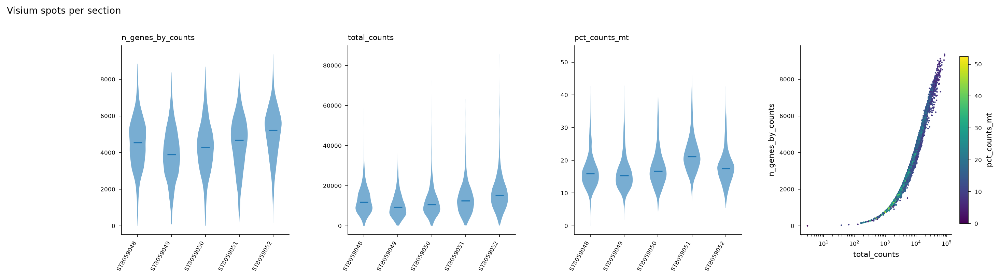

In [36]:
scn.calc_qc_metrics(adata_vis)

# MT genes were removed in section 3; their counts are in obsm['MT'] -> mito % of all counts
mt_counts = np.asarray(adata_vis.obsm['MT']).sum(1)

adata_vis.obs['pct_counts_mt'] = 100 * mt_counts / (adata_vis.obs['total_counts'].values + mt_counts)

fig = scn.plot_qc(adata=adata_vis, fname=fig_qc_visium, title='Visium spots per section')
plt.show()

In [35]:
df_qc_vis = scn.calc_df_qc(adata=adata_vis)
df_qc_vis

,n,median_n_genes_by_counts,median_total_counts,median_pct_counts_mt,q25_n_genes_by_counts,q25_total_counts,q25_pct_counts_mt,q75_n_genes_by_counts,q75_total_counts,q75_pct_counts_mt
sample,,,,,,,,,,
ST8059048,2987,4541.0,11736.0,15.930000,3537.00,7968.00,13.28,5463.50,16634.5,18.92
ST8059049,3499,3885.0,9206.0,15.300000,2946.50,5838.00,12.65,4877.00,13605.5,18.39
ST8059050,3497,4281.0,10589.0,16.740000,3327.00,7069.00,13.89,5166.00,14978.0,20.31
ST8059051,2409,4669.0,12543.0,21.200001,3567.00,8145.00,18.26,5563.00,17415.0,24.90
ST8059052,2576,5215.5,15209.5,17.559999,4165.25,10570.75,14.72,6003.25,20370.0,20.55


#### adata_ref

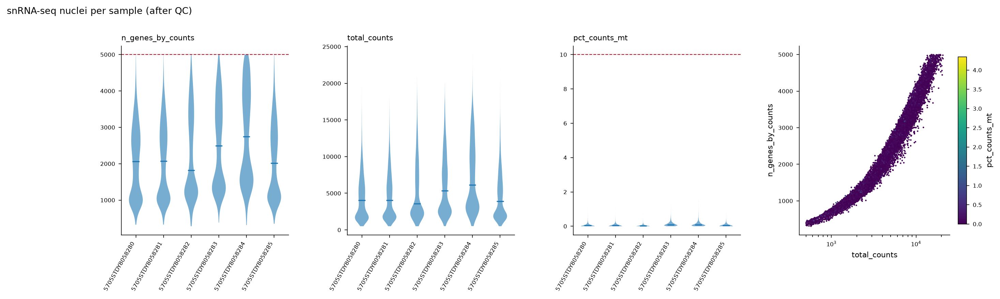

In [39]:
fig = scn.plot_qc(adata=adata_ref, fname=fig_qc_snrna, title='snRNA-seq nuclei per sample (after QC)',
                 thresholds={'n_genes_by_counts': scn.params['snrna_max_genes'],
                             'pct_counts_mt': 100 * scn.params['snrna_max_mt_frac']})
plt.show()

In [40]:
df_qc_ref = scn.calc_df_qc(adata=adata_ref)
df_qc_ref

,n,median_n_genes_by_counts,median_total_counts,median_pct_counts_mt,q25_n_genes_by_counts,q25_total_counts,q25_pct_counts_mt,q75_n_genes_by_counts,q75_total_counts,q75_pct_counts_mt
sample,,,,,,,,,,
5705STDY8058280,8147,2060.0,4031.0,0.04,1111.00,1875.00,0.00,2831.0,6527.00,0.08
5705STDY8058281,8250,2070.0,4062.5,0.04,1121.00,1894.25,0.00,2921.0,6772.00,0.08
5705STDY8058282,5789,1820.0,3602.0,0.02,1215.00,2204.00,0.00,3304.0,8099.00,0.05
5705STDY8058283,5212,2497.5,5344.0,0.08,1414.00,2613.00,0.04,3570.0,9048.00,0.16
5705STDY8058284,2890,2747.5,6145.5,0.08,1605.25,3196.00,0.03,3920.5,10799.25,0.15
5705STDY8058285,10242,2012.5,3928.5,0.05,1147.25,1972.00,0.01,2908.0,6746.25,0.09


In [41]:
df_ct_sample = pd.crosstab(adata_ref.obs[scn.params['celltype_col']], adata_ref.obs[scn.sample_col])
print("cell types present in all 6 samples:", int((df_ct_sample > 0).all(1).sum()), "of", len(df_ct_sample))
df_ct_sample.head(10)

cell types present in all 6 samples: 53 of 59


sample,5705STDY8058280,5705STDY8058281,5705STDY8058282,5705STDY8058283,5705STDY8058284,5705STDY8058285
annotation_1,,,,,,
Astro_AMY,36,89,63,89,64,157
Astro_AMY_CTX,76,92,41,24,7,39
Astro_CTX,110,98,25,60,33,117
Astro_HPC,48,53,29,24,24,83
Astro_HYPO,91,88,53,72,61,86
Astro_STR,2,8,0,28,12,31
Astro_THAL_hab,6,5,17,5,2,8
Astro_THAL_lat,69,54,45,34,23,107
Astro_THAL_med,82,67,94,41,32,89


### 5. UMAP - broad classes and 59 subtypes (Fig 2B)

The UMAP coordinates, **annotation_1** and **broad_class** are the paper's (cellxgene object); only obs and obsm are read.

In [42]:
fname_umap

'snrna/mouse_brain_snRNA_with_UMAP_cellxgene.h5ad'

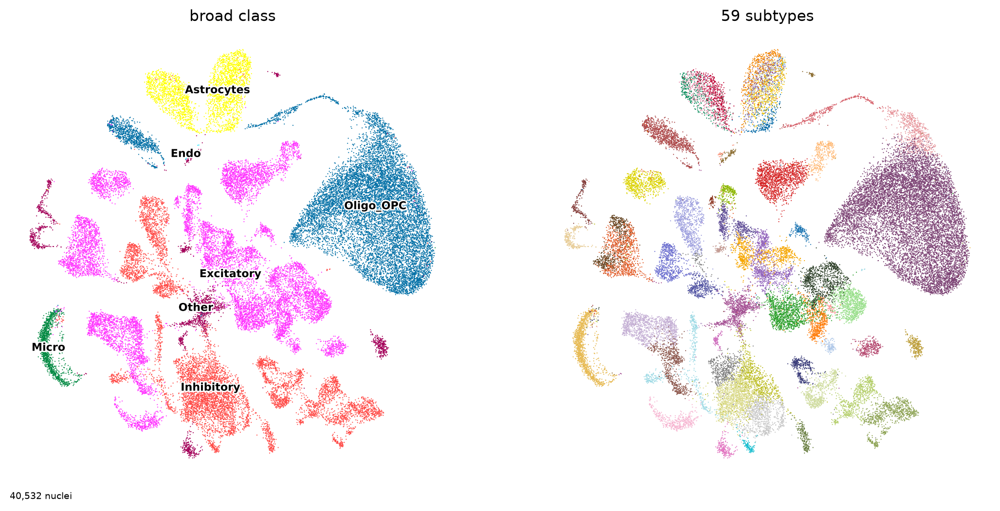

broad_class,Excitatory,Oligo_OPC,Inhibitory,Astrocytes,Other,Micro,Endo
n_nuclei,13014,12747,8471,3013,2047,1218,22


In [19]:
adata_umap = scn.load_umap_obs(fname_umap)
fig = scn.plot_umap_broad_subtypes(adata_umap, fname=fig_2B)
plt.show()
adata_umap.obs[scn.params['broad_col']].value_counts().to_frame('n_nuclei').T

### 6. Anatomical regions, major regional subtypes, sparse cell types, fine anatomical subtypes (Fig 2C-F)

The paper's cell2location map gives cells per spot (**q05_spot_factors<type>**, 59 types) and **region_cluster** (Leiden on abundance; paper Methods: kNN 38, resolution 1.3).

Each region cluster is named by the cell types most enriched in it (cluster mean / slide mean), using **region_celltype_map**.

In [44]:
adata_map.obs.columns

Index(['in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'mt_frac', 'sample_name', 'sample_name2', 'image_name', 'slide', 'position', 'leiden', 'region_cluster', 'region_label', 'cortical_layer'],
      dtype='object')

In [48]:
cols=['in_tissue', 'array_row', 'array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 
      'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes',
       'pct_counts_in_top_500_genes', 'mt_frac', 'sample_name', 'sample_name2', 'image_name', 'slide', 'position', 'leiden', 
       'region_cluster', 'region_label', 'cortical_layer']

cols=['array_col', 'sample', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 
      'log1p_total_counts',  'sample_name', 'image_name', 'slide', 'position', 'leiden', 
       'region_cluster', 'region_label', 'cortical_layer']

adata_map.obs[cols].head(3).T

spot_id,ST8059048_AAACAAGTATCTCCCA-1,ST8059048_AAACACCAATAACTGC-1,ST8059048_AAACAGAGCGACTCCT-1
array_col,102,19,94
sample,ST8059048,ST8059048,ST8059048
n_genes_by_counts,4678,3549,6779
log1p_n_genes_by_counts,8.45084,8.174703,8.821732
total_counts,14284.0,9951.0,32155.0
log1p_total_counts,9.566965,9.205529,10.378354
sample_name,ST8059048,ST8059048,ST8059048
image_name,mouse_brain_he_Library_028_C05717_020_C1_144600.jpg,mouse_brain_he_Library_028_C05717_020_C1_144600.jpg,mouse_brain_he_Library_028_C05717_020_C1_144600.jpg
slide,C05717-020,C05717-020,C05717-020
position,C1,C1,C1


In [49]:
regions = np.unique(adata_map.obs.region_label)
regions

array(['AMY', 'CTX_L1', 'CTX_L2/3', 'CTX_L4', 'CTX_L5', 'CTX_L5/6',
       'CTX_L6b', 'HAB', 'HPC_CA1', 'HPC_CA3', 'HPC_DG', 'HYPO', 'PIR',
       'STR', 'THAL', 'WM', 'edge_LowQ'], dtype=object)

### Brain regions

In [52]:
fname = 'mouse_brain_regions.tsv'
dfr = pdreadcsv(fname, root_data, verbose=True)
dfr

Table opened ((17, 7)) at '/home/flavio/uv/cell_cell_communication/mouse_brain/data/mouse_brain_regions.tsv'


,region_id,region_name,category,description,defining_cell_types,region_clusters,n_spots
0,AMY,Amygdala,cortical subplate / pallium,"Group of nuclei in the ventral temporal pole (basolateral and cortical amygdala); emotional learning, fear and rewar...","Ext_Amy_1, Ext_Amy_2, Astro_AMY","4,25",338
1,CTX_L1,Isocortex layer 1 (molecular layer),isocortex,"Cell-sparse outermost layer under the pia: apical dendrites of pyramidal neurons, Lamp5 interneurons and astrocytes....","Inh_Lamp5, Astro_AMY_CTX, Astro_HPC",11,210
2,CTX_L2/3,Isocortex layers 2/3,isocortex,Supragranular layers of intratelencephalic (IT) pyramidal neurons projecting to other cortical areas; site of local ...,Ext_L23,3,327
3,CTX_L4,Isocortex layer 4 (granular layer),isocortex,Main input layer receiving thalamocortical afferents; prominent in primary sensory areas such as the somatosensory c...,"Ext_L25 (L2-5 IT, peak in L4)",18,143
4,CTX_L5,Isocortex layer 5,isocortex,"Infragranular output layer with large pyramidal-tract (PT) neurons projecting to brainstem and spinal cord, plus IT ...","Ext_L5_1, Ext_L5_2","1,19",496
5,CTX_L5/6,Isocortex layers 5/6 boundary,isocortex,"Deep cortical band of near-projecting / IT neurons at the L5-L6 border, co-enriched for layer 6 corticothalamic type...","Ext_L56, Ext_L6",2,358
6,CTX_L6b,Isocortex layer 6b,isocortex,Thin deepest cortical layer (subplate remnant) directly above the white matter.,Ext_L6B,17,144
7,HAB,Habenula and adjacent epithalamus,diencephalon (epithalamus),Medial and lateral habenular nuclei dorsal to the thalamus; relay between forebrain and midbrain monoaminergic centr...,"Ext_Med, Inh_6, Astro_THAL_hab","13,14,26",360
8,HPC_CA1,"Hippocampus, field CA1",hippocampal formation,Pyramidal layer of Ammon's horn field CA1; main hippocampal output to subiculum and entorhinal cortex.,Ext_Hpc_CA1,24,68
9,HPC_CA3,"Hippocampus, fields CA3 (with CA2)",hippocampal formation,Pyramidal layer of fields CA3 and CA2; recurrent autoassociative network receiving mossy fibres from the dentate gyrus.,"Ext_Hpc_CA3, Ext_Hpc_CA2",20,129


![mb01_brain_regions](../mouse_brain/figures/mb01_brain_regions.png)

In [55]:
df_brain_regions = pdreadcsv('mouse_brain_regions.tsv', root_data)
regions = dict(zip(df_brain_regions.region_id, df_brain_regions.region_name))   # 'CTX_L4' -> 'Isocortex layer 4 (granular layer)'

fig = scn.plotly_spatial_visium(names=regions, adata=adata_map, key='region_label', library_id='ST8059048')
fig.show()
fig.write_html(root_figure / 'mb01_brain_regions_ST8059048.html', include_plotlyjs=True)

### Cell types

In [57]:
cell_types = adata_map.uns['mod']['factor_names']
cell_types

array(['Astro_AMY', 'Astro_AMY_CTX', 'Astro_CTX', 'Astro_HPC',
       'Astro_HYPO', 'Astro_STR', 'Astro_THAL_hab', 'Astro_THAL_lat',
       'Astro_THAL_med', 'Astro_WM', 'Endo', 'Ext_Amy_1', 'Ext_Amy_2',
       'Ext_ClauPyr', 'Ext_Hpc_CA1', 'Ext_Hpc_CA2', 'Ext_Hpc_CA3',
       'Ext_Hpc_DG1', 'Ext_Hpc_DG2', 'Ext_L23', 'Ext_L25', 'Ext_L56',
       'Ext_L5_1', 'Ext_L5_2', 'Ext_L5_3', 'Ext_L6', 'Ext_L6B', 'Ext_Med',
       'Ext_Pir', 'Ext_Thal_1', 'Ext_Thal_2', 'Ext_Unk_1', 'Ext_Unk_2',
       'Ext_Unk_3', 'Inh_1', 'Inh_2', 'Inh_3', 'Inh_4', 'Inh_5', 'Inh_6',
       'Inh_Lamp5', 'Inh_Meis2_1', 'Inh_Meis2_2', 'Inh_Meis2_3',
       'Inh_Meis2_4', 'Inh_Pvalb', 'Inh_Sst', 'Inh_Vip', 'LowQ_1',
       'LowQ_2', 'Micro', 'Nb_1', 'Nb_2', 'OPC_1', 'OPC_2', 'Oligo_1',
       'Oligo_2', 'Unk_1', 'Unk_2'], dtype='<U14')

In [58]:
fname = 'mouse_brain_cell_types.tsv'
dfct = pdreadcsv(fname, root_data, verbose=True)
dfct

Table opened ((59, 9)) at '/home/flavio/uv/cell_cell_communication/mouse_brain/data/mouse_brain_cell_types.tsv'


,cell_type_id,cell_type_name,broad_class,n_nuclei,main_region,main_region_enrich,second_region,top_signature_genes,description
0,Astro_AMY,Amygdala astrocytes,Astrocytes,498,AMY,3.3,STR,"Wdr17, Apoe, Slc1a3, Gpc5, Slc1a2, Plpp3",Telencephalic grey-matter astrocytes enriched in the amygdala (paper Fig 3 regional astrocyte subtype).
1,Astro_AMY_CTX,Amygdala / cortex astrocytes,Astrocytes,279,CTX_L2/3,2.6,CTX_L1,"Slc1a3, Wdr17, Slc1a2, Gpc5, Apoe, Mertk",Telencephalic astrocytes shared by amygdala and cortex; here enriched in upper cortical layers and layer 1.
2,Astro_CTX,Cortical astrocytes,Astrocytes,443,CTX_L4,5.4,CTX_L2/3,"Slc1a2, Wdr17, Gpc5, Slc1a3, Luzp2, Prex2","Grey-matter astrocytes of the isocortex, most enriched in middle layers (L4, L2/3)."
3,Astro_HPC,Hippocampal astrocytes,Astrocytes,261,HPC_DG,7.3,HPC_CA3,"Slc1a2, Wdr17, Slc1a3, Gpc5, Apoe, Cst3","Astrocytes of the hippocampal formation, enriched around the dentate gyrus and CA3."
4,Astro_HYPO,Hypothalamic astrocytes,Astrocytes,451,HYPO,6.1,HAB,"Itih3, Slc6a11, Slc4a4, Nhsl1, Trpm3, Apoe","Diencephalic astrocytes of the hypothalamus (Slc6a11, Itih3); paper Fig 3 HYPO subtype."
5,Astro_STR,Striatal astrocytes,Astrocytes,81,HPC_CA1,3.2,HPC_CA3,"Prex2, Slc1a2, Cst3, Wdr17, Slc1a3, Apoe","Rare striatal astrocyte subtype (81 nuclei); in this map its density peaks in hippocampal CA1 rather than striatum, ..."
6,Astro_THAL_hab,Habenular astrocytes,Astrocytes,43,HAB,4.2,WM,"Pdgfd, Apoe, Agt, Slc6a11, Slc4a4, Gja1","Diencephalic astrocytes of the habenula (Agt, Slc6a11); paper Fig 3 THAL_hab subtype."
7,Astro_THAL_lat,Lateral thalamic astrocytes,Astrocytes,332,THAL,4.8,HAB,"Aldh1a1, Gpc5, Nhsl1, Atp1a2, Trpm3, Gm12239",Diencephalic astrocytes of the lateral thalamus (Aldh1a1); paper Fig 3 THAL_lat subtype.
8,Astro_THAL_med,Medial thalamic astrocytes,Astrocytes,405,THAL,5.6,HAB,"Nhsl1, A330076C08Rik, Slc6a11, Slc4a4, Trpm3, Atp1a2","Diencephalic astrocytes of the medial thalamus (Slc6a11, Slc4a4); paper Fig 3 THAL_med subtype."
9,Astro_WM,White-matter astrocytes,Astrocytes,220,WM,5.0,HAB,"Thbs4, Apoe, Cst3, Wdr17, Gfap, Gm10561","Fibrous astrocytes of the fibre tracts (Gfap, Thbs4)."


### Abundance of cell types in regions

In [20]:
adata_map = scn.load_paper_map(fname_map)
df_abund = scn.calc_df_abundance(adata_map)
print(adata_map.shape, scn.library_ids(adata_map), df_abund.shape)
df_regions = scn.calc_df_regions(adata_map)
df_regions

(5396, 31040) ['ST8059048', 'ST8059051'] (5396, 59)


,region_cluster,n_spots,label,top_types,top_enrich,label_votes
0,0,421,WM,Oligo_2 / OPC_2 / Astro_WM,6.0 / 5.6 / 5.0,WM:15.1
1,1,365,CTX_L5,Ext_L5_2 / LowQ_2 / Ext_Med,12.1 / 9.7 / 6.6,CTX_L5:16.8; HAB:6.6
2,2,358,CTX_L5/6,Ext_L56 / Ext_ClauPyr / Ext_L6,11.0 / 10.5 / 8.3,CTX_L5/6:11.0; CLA:10.5; CTX_L6:8.3
3,3,327,CTX_L2/3,Ext_L23 / Inh_Vip / Ext_Med,12.4 / 4.4 / 3.6,CTX_L2/3:12.4; HAB:3.6; CTX_L4:3.4
4,4,296,AMY,Ext_Amy_2 / Inh_Sst / Inh_Vip,14.1 / 4.1 / 3.1,AMY:16.6; STR:2.3
5,5,294,THAL,Ext_Thal_2 / Ext_Unk_3 / Astro_THAL_med,14.8 / 11.1 / 6.6,THAL:24.5
6,6,289,STR,Inh_Meis2_2 / Inh_Meis2_3 / Astro_STR,16.9 / 16.5 / 4.4,STR:37.8
7,7,279,PIR,Ext_Pir / Astro_AMY_CTX / Ext_Unk_1,14.5 / 2.3 / 2.0,PIR:14.5; AMY:1.6
8,8,258,STR,Inh_1 / Inh_Meis2_1 / Inh_4,14.5 / 13.1 / 5.9,STR:13.1; AMY:4.2; HYPO:3.9
9,9,231,THAL,Ext_Thal_1 / Astro_THAL_lat / Astro_THAL_med,8.1 / 5.6 / 5.0,THAL:18.7


**Edge check.** Two clusters are not labelled well by enrichment alone. A Visium spot has 6 neighbours; spots on the tissue border have fewer. Cluster 11 (Inh_Lamp5, Astro enriched) lies on the pial surface: it is **cortical layer 1**. Cluster 21 (LowQ_1) is a tissue-rim artefact. Both are set with **region_label_override**.

In [21]:
df_edge = scn.calc_df_edge_fraction(adata_map)
df_regions_edge = df_regions.set_index('region_cluster').join(df_edge)
df_regions_edge.loc[df_regions_edge.mean_frac_edge > 0.25, ['label', 'top_types', 'mean_frac_edge']]

,label,top_types,mean_frac_edge
region_cluster,,,
11,HPC,Astro_HPC / Astro_AMY_CTX / Inh_Lamp5,0.638
12,HPC_DG,Ext_Hpc_DG1 / Ext_Hpc_DG2 / Nb_1,0.312
21,WM,LowQ_1 / Astro_WM / Endo,0.781
26,HAB,Inh_6 / Astro_THAL_hab / Astro_WM,0.421


In [22]:
scn.add_region_labels(df_regions, adata_map)
df_regions['label_final'] = df_regions.region_cluster.map(lambda c: scn.params['region_label_override'].get(c))
df_regions['label_final'] = df_regions['label_final'].fillna(df_regions['label'])
pdwritecsv(df_regions.join(df_edge[['mean_frac_edge']], on='region_cluster'), tsv_regions, root_result)
adata_map.obs['region_label'].value_counts().to_frame('n_spots').T

region_label,THAL,STR,CTX_L5,WM,HYPO,HAB,CTX_L5/6,AMY,CTX_L2/3,PIR,CTX_L1,HPC_DG,CTX_L6b,CTX_L4,HPC_CA3,edge_LowQ,HPC_CA1
n_spots,796,622,496,421,384,360,358,338,327,279,210,202,144,143,129,119,68


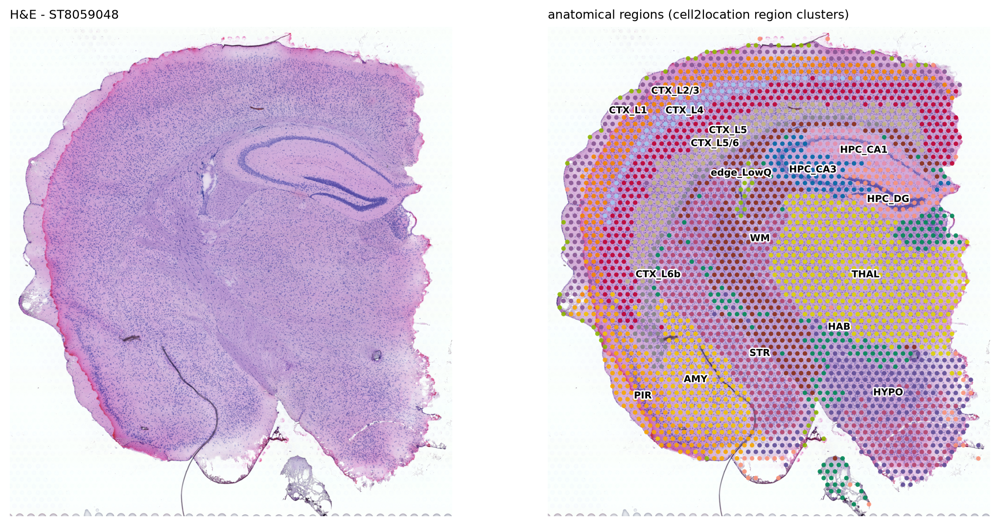

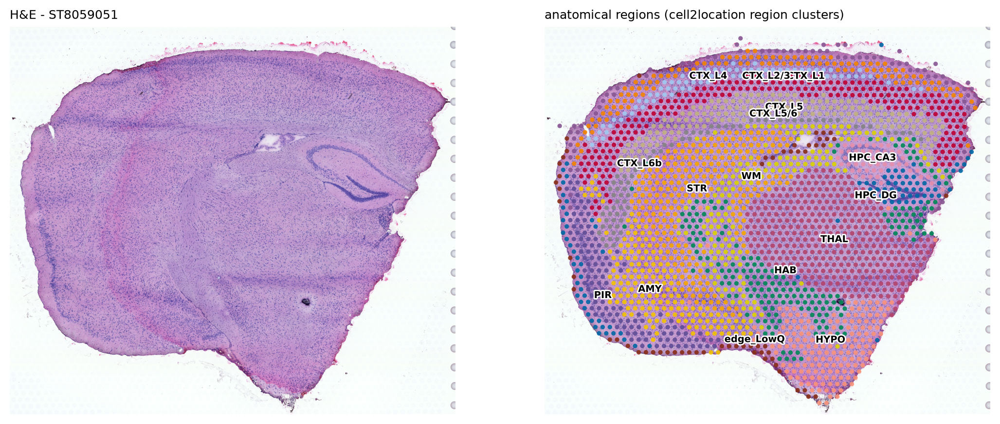

In [23]:
for lib in scn.library_ids(adata_map):
    fig = scn.plot_regions_he(adata_map, library_id=lib, fname=fig_2C.format(lib=lib))
    plt.show()

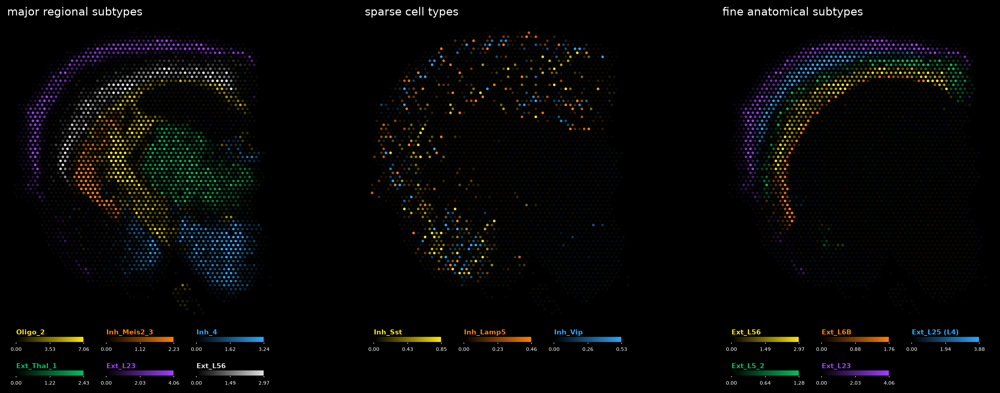

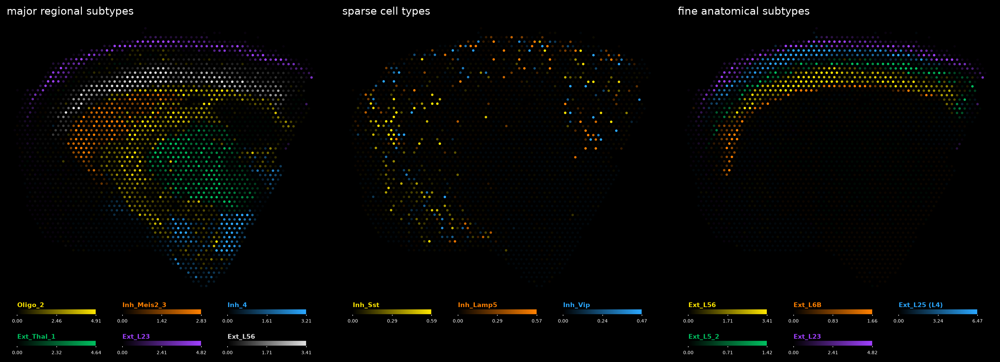

,panel,cell_type,cap_cells_per_spot
0,major regional subtypes,Oligo_2,4.914
1,major regional subtypes,Inh_Meis2_3,2.833
2,major regional subtypes,Inh_4,3.211
3,major regional subtypes,Ext_Thal_1,4.643
4,major regional subtypes,Ext_L23,4.824
5,major regional subtypes,Ext_L56,3.410
6,sparse cell types,Inh_Sst,0.588
7,sparse cell types,Inh_Lamp5,0.571
8,sparse cell types,Inh_Vip,0.472
9,fine anatomical subtypes,Ext_L56,3.410


In [24]:
panels = {'major regional subtypes': scn.params['fig2D_types'],
          'sparse cell types': scn.params['fig2E_types'],
          'fine anatomical subtypes': scn.params['fig2F_types']}
for lib in scn.library_ids(adata_map):
    fig = scn.plot_density_panels(panels, adata_map, library_id=lib, df_abund=df_abund, fname=fig_2DEF.format(lib=lib))
    plt.show()
fig.df_caps

Colour scale per cell type: 0 to the 99.2% quantile of cells per spot. **Ext_L25** (L2-5 IT neurons, peak in L4) is shown as **Ext_L25 (L4)**: the 59-type annotation has no **Ext_L4**, the label used in Fig 2F.

## 7. Slide-seq V2 (Fig 2H)

The 59 snRNA signatures (paper NB regression) are mapped to a Slide-seqV2 puck of the mouse hippocampus (Stickels et al. 2021). Paper priors for 10-µm beads: 1 cell and 1 cell type per location.

squidpy stores **X = log1p(normalize_total)** on 4,000 HVGs with the raw library size in **obs['total_counts']**; counts are recovered exactly as **expm1(X) * total_counts / target**.

In [25]:
adata_ss, df_sig_ss, diag_ss = scn.prepare_slideseq_mapping(fname_slideseq, fname_signatures)
print(adata_ss.shape, diag_ss)

(41786, 4000) {'target_sum': 432.00001287460327, 'max_err': 0.49910529947726445, 'frac_values_err_gt_tol': 0.00018002767528721103, 'median_err': 1.0321363177467902e-06, 'n_genes_shared': 2528}


In [26]:
run_dir_ss = root_result / f'c2l_slideseq_{c2l_tag_slideseq}'
if (run_dir_ss / 'sp.h5ad').exists() or c2l_train_if_missing:
    adata_ss_map = scn.train_mapping(adata_ss, df_sig_ss, run_dir_ss, N_cells_per_location=scn.params['slideseq_N'],
                                    detection_alpha=scn.params['slideseq_alpha'], max_epochs=c2l_max_epochs,
                                    A_factors_per_location=scn.params['slideseq_A'],
                                    B_groups_per_location=scn.params['slideseq_B'])
    print(adata_ss_map.shape, {k: v for k, v in adata_ss_map.uns['c2l_training'].items() if k != 'elbo_history'})
else:
    adata_ss_map = None
    print(f"no cached run in {run_dir_ss}: run src/programs/run_c2l_mouse_brain.py --mode slideseq")

(41786, 2528) {'N_cells_per_location': 1, 'accelerator': 'auto', 'detection_alpha': 20, 'max_epochs': 2000, 'n_genes': 2528}


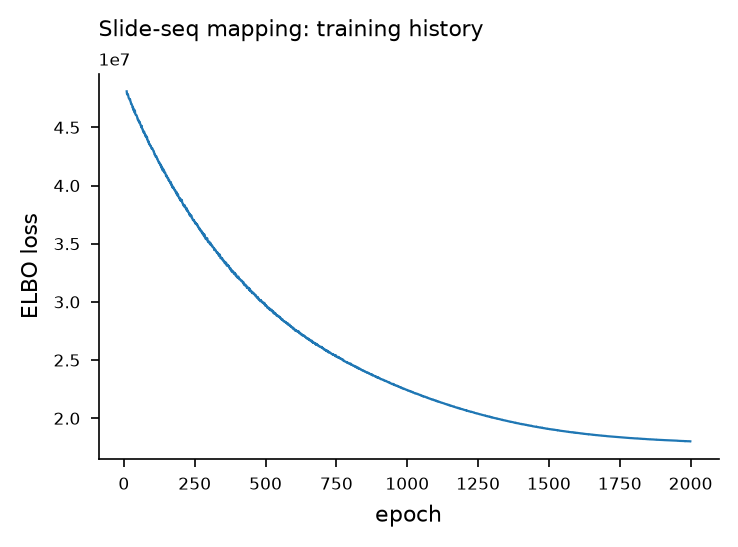

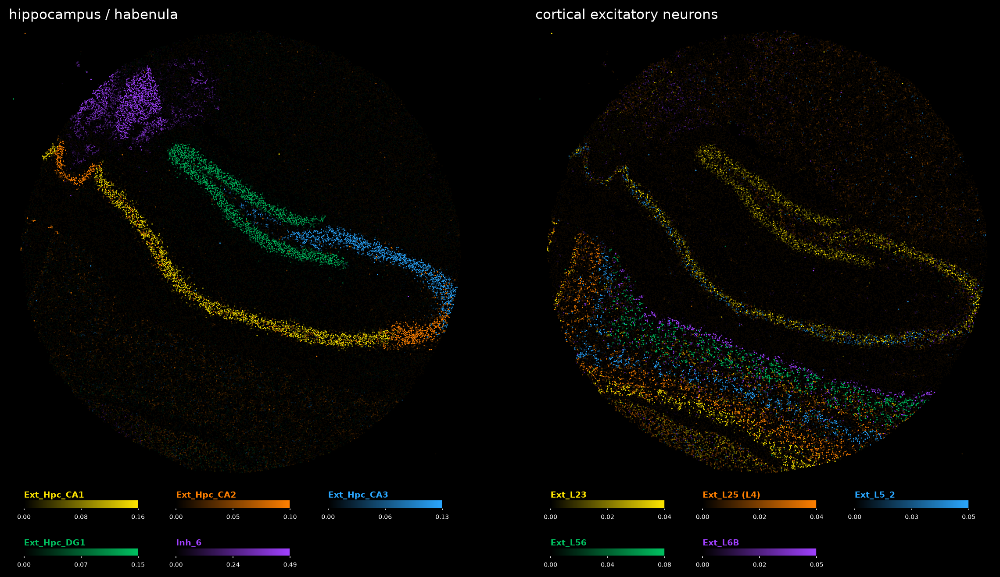

In [27]:
if adata_ss_map is not None:
    elbo = np.asarray(adata_ss_map.uns['c2l_training']['elbo_history'])
    fig, ax = plt.subplots(figsize=(4, 2.5))
    ax.plot(np.arange(len(elbo))[10:], elbo[10:], lw=0.8)
    ax.set_xlabel('epoch'); ax.set_ylabel('ELBO loss'); ax.set_title('Slide-seq mapping: training history')
    plt.show()
    fig = scn.plot_slideseq(adata_ss_map, fname=fig_2H)
    plt.show()

## 8. Quantitative validation workflow based on scRNA-seq from manually dissected layers (Fig 2I)

Allen Smart-seq cells from the primary somatosensory cortex (SSp) were dissected by layer (Yao et al. 2020). Following the paper:

- cell types of SSp plus types exclusive to the hippocampal subiculum (PAR-POST-PRE), with ≥ 3 cells
- signatures = per-cluster average expression (NB regression is not suited to Smart-seq)
- mapped with cell2location to the Visium cortical-layer spots (here: region clusters CTX_L1 ... CTX_L6b)

In [28]:
adata_allen = scn.read_h5ad(fname_allen, set_self=False)
scn.sanitize_allen_types(adata_allen)          # '166_L2/3 IT CTX' -> '166_L2-3 IT CTX' ('/' is not allowed in h5ad keys)
df_meta_allen = adata_allen.obs
df_type_counts, types_ssp, types_hpc = scn.allen_select_types(df_meta_allen)
print(f"Allen cells: {adata_allen.n_obs:,} ({df_meta_allen[scn.params['allen_region_col']].value_counts().to_dict()}); "
      f"types: SSp {len(types_ssp)} + hippocampus-exclusive {len(types_hpc)} = {len(types_ssp) + len(types_hpc)}")
df_allen_counts, df_allen_prop = scn.calc_df_allen_layer_prop(df_meta_allen, types_ssp)
df_allen_counts.sum().to_frame('cells per layer (SSp)').T

Allen cells: 7,249 ({'SSp': 5665, 'PAR-POST-PRE': 1584}); types: SSp 104 + hippocampus-exclusive 34 = 138


_layer,L1,L2/3,L4,L5,L6
cells per layer (SSp),32,1183,992,741,2157


{'L1': 210, 'L2/3': 327, 'L4': 143, 'L5': 496, 'L6': 502}


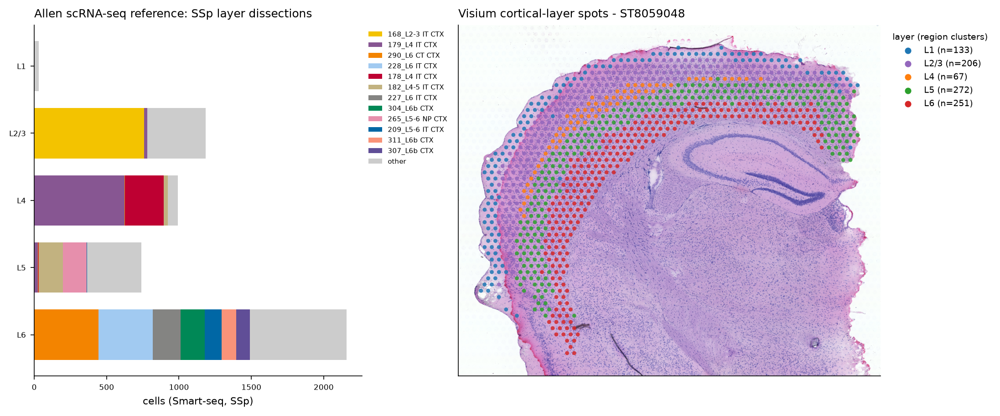

In [29]:
scn.assign_cortical_layers(adata_map)
print(adata_map.obs['cortical_layer'].value_counts().reindex(list(scn.params['layers'])).to_dict())
fig = scn.plot_layer_workflow(adata_map, library_id=library_main, df_allen_counts=df_allen_counts, fname=fig_2I)
plt.show()

## 9. Heatmap of relative cell subtype proportion (Fig 2J)

Proportion of each cell type within each layer: Allen = cell counts of the SSp layer dissections; cell2location = mean estimated density per layer, normalised over all mapped types. Shown are the 23 most prevalent SSp-exclusive types (count in SSp > 15, absent from the hippocampal region).

/home/flavio/uv/cell_cell_communication/.venv/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)


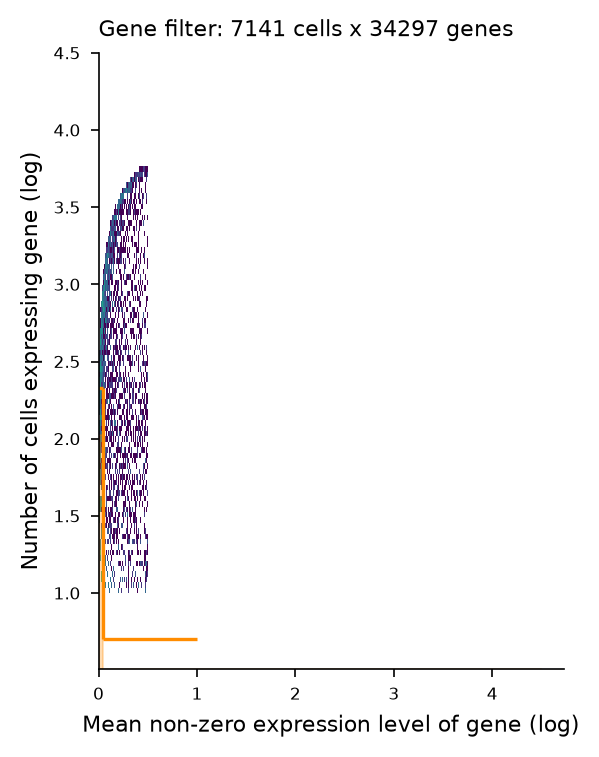

{'n_types_ssp': 104, 'n_types_hpc': 34, 'n_genes_filtered': 34297, 'n_spots': 1678, 'n_genes_shared': 19884}
(1678, 19884) {'N_cells_per_location': 8, 'accelerator': 'cpu', 'detection_alpha': 20, 'max_epochs': 3000, 'n_genes': 19884, 'note': 'posterior exported from the saved model'}


In [30]:
run_dir_allen = root_result / f'c2l_allen_ssp_{c2l_tag_allen}'
if (run_dir_allen / 'sp.h5ad').exists() or c2l_train_if_missing:
    adata_ctx, df_sig_allen, info_allen = scn.prepare_allen_mapping(adata_allen, adata_map)
    print({k: v for k, v in info_allen.items() if k not in ('types', 'df_type_counts')})
    adata_allen_map = scn.train_mapping(adata_ctx, df_sig_allen, run_dir_allen, N_cells_per_location=scn.params['c2l_allen_N'],
                                       detection_alpha=scn.params['c2l_allen_alpha'], max_epochs=c2l_max_epochs,
                                       batch_key=scn.sample_col, A_factors_per_location=scn.params['c2l_allen_A'])
    # layers from the current region labels (the cached obs may predate a change of layer_from_region)
    adata_allen_map.obs['cortical_layer'] = adata_map.obs.loc[adata_allen_map.obs_names, 'cortical_layer'].values
    print(adata_allen_map.shape, {k: v for k, v in adata_allen_map.uns['c2l_training'].items() if k != 'elbo_history'})
else:
    adata_allen_map = None
    print(f"no cached run in {run_dir_allen}: run src/programs/run_c2l_mouse_brain.py --mode allen")

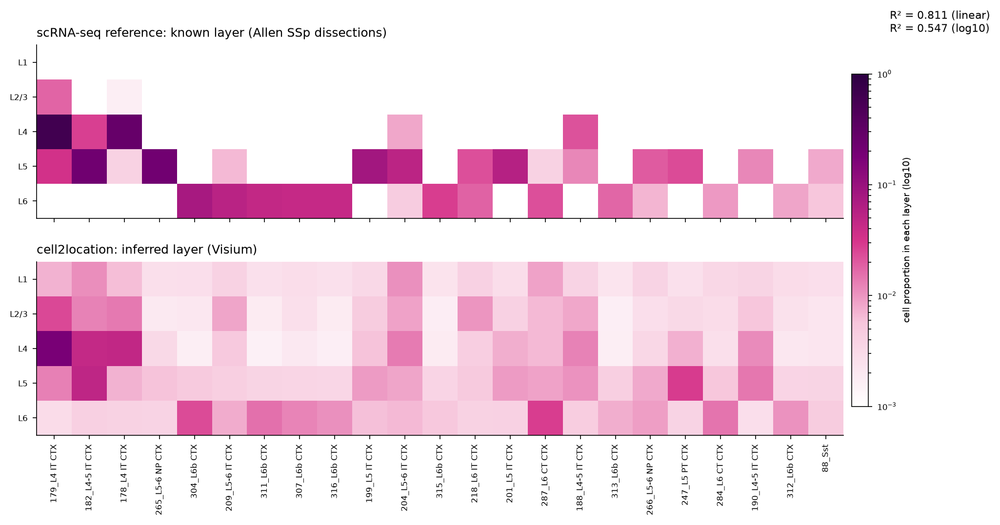

{'R2_linear': np.float64(0.8111350561058089), 'R2_log10': np.float64(0.5472576567269589), 'n_cells_compared': 115}


In [31]:
if adata_allen_map is not None:
    types_top = scn.allen_top_types(df_type_counts)
    df_c2l_prop = scn.calc_df_c2l_layer_prop(adata_allen_map, scn.calc_df_abundance(adata_allen_map).columns)
    fig, stats_2J = scn.plot_layer_heatmaps(df_allen_prop, df_c2l_prop, types_top, fname=fig_2J)
    plt.show()
    print(stats_2J)
    df_layer_prop = pd.concat({'allen': df_allen_prop.reindex(types_top), 'cell2location': df_c2l_prop.reindex(types_top)}, axis=1)
    df_layer_prop.columns = [f'{a}_{l}' for a, l in df_layer_prop.columns]
    pdwritecsv(df_layer_prop.round(5).reset_index(names='cell_type'), tsv_layer, root_result)
    df_layer_prop.round(3)

### Notes for interpretation

- Fig 2C-F come from the paper's own cell2location run; region names are rule-based (**region_celltype_map**, **region_label_override**) and can be edited in **params**.
- Fig 2H and 2J are new cell2location runs. The cached CPU runs use fewer epochs than the paper (30,000), so densities are less converged; check the ELBO curves and rerun on GPU for final figures.
- Fig 2J compares layers defined by **transcriptomic region clusters** across the whole cortex of 2 sections, whereas the paper used histology-based SSp layers of 5 sections. Agreement is therefore expected to be lower and partly reflects how the layer clusters were defined.